# Benchmark preditivo dos nuisance models — SINASC 2024 (08C)

Comparação pré-especificada de famílias para propensity e outcomes, preservando C1/C2 e os artefatos históricos.

In [1]:
from pathlib import Path
import gc
import hashlib
import json
import sys
import time

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

raiz = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "src").exists()).resolve()
sys.path.insert(0, str(raiz))
assert Path(sys.executable).resolve() == (raiz / ".venv/Scripts/python.exe").resolve()
from src.amostra import carregar_exercicio
from src.diagnosticos import COLUNAS_PROPENSITY_PRINCIPAL
from src.benchmark_nuisance import (
    SEED, amostra_viabilidade, candidatos, executar_familia, executar_outcome,
    media_macro, medir_viabilidade,
)
from src.visualizacao import configurar_plotly, aplicar_tema_ipt

configurar_plotly()
pasta_saida = raiz / "outputs/temporal/modelos_nuisance"
pasta_cache = raiz / "data/interim/nuisance_benchmark"
pasta_saida.mkdir(parents=True, exist_ok=True)
pasta_cache.mkdir(parents=True, exist_ok=True)
def salvar_csv(tabela, nome):
    tabela.to_csv(pasta_saida / nome, index=False, float_format="%.12g")
def salvar_json_novo_ou_validar(objeto, nome):
    caminho = pasta_saida / nome
    if caminho.exists():
        assert json.loads(caminho.read_text(encoding="utf-8")) == objeto, f"Contrato divergente: {nome}"
    else:
        caminho.write_text(json.dumps(objeto, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    return caminho
print("Raiz:", raiz)

Raiz: C:\GitHub\data-science-projects\projetos\big-data-sinasc-causal-ml


## 1. Objetivo

Verificar se novas famílias oferecem ganho preditivo material nos modelos auxiliares de 2024. O propensity e os modelos de outcome são avaliados separadamente.

In [2]:
parquet = raiz / "data/processed/sinasc_2024.parquet"
parquet_sha = hashlib.sha256(parquet.read_bytes()).hexdigest()
assert parquet_sha == "a7a1618e555d1417f692b5334b2a0fd01cfee911b3d45c0e0623346f3b8a12b5"
dados, x, t, y, provenance = carregar_exercicio(raiz)
assert len(x) == 2_251_570 and int((t == 0).sum()) == 309_525 and int((t == 1).sum()) == 1_942_045
assert dados.contador.notna().all() and dados.contador.is_unique
assert provenance["parquet_sha256"] == parquet_sha
assert list(x.columns) == list(COLUNAS_PROPENSITY_PRINCIPAL)
assert not {"tratamento", "Y_BAIXO_PESO", "contador"}.intersection(x.columns)
assert set(np.unique(y)) == {0, 1}
contrato = {"ano": 2024, "dados_sha256": parquet_sha,
            "chave_sha256": hashlib.sha256("\n".join(dados.contador.astype(str)).encode()).hexdigest(),
            "n": len(x), "n_t0": int((t == 0).sum()), "n_t1": int((t == 1).sum()),
            "features": list(x.columns), "seed": SEED}
display(pd.Series({k:v for k,v in contrato.items() if k != "features"}, name="contrato").to_frame())

,contrato
ano,2024
dados_sha256,a7a1618e555d1417f692b5334b2a0fd01cfee911b3d45c...
chave_sha256,2b6d49e6c62e552cff9c8cf00355d0ee55ae737f89a857...
n,2251570
n_t0,309525
n_t1,1942045
seed,20240925


## 2. Estado dos nuisance models certificados

Propensity principal P0: logística L2 C=1, `lbfgs`, 500 iterações, tolerância 1e−5; imputação, escala e one-hot. Outcome C1: mesma logística em cada braço. Outcome C2 e propensity C3 de robustez: HGB, 100 iterações, 15 folhas, folha mínima 100, taxa 0,1, L2=1, parada antecipada. Heterogeneidade HGB/Ridge permanece fora desta rodada.

In [3]:
inventario = pd.DataFrame([
    ["propensity P0", "LogisticRegression", "C=1; lbfgs; max_iter=500; tol=1e-5", "Fase 2/08/08B", "baseline certificado"],
    ["outcome m0/m1 C1", "LogisticRegression", "mesma especificação, por braço", "Fase 2", "preservado"],
    ["outcome m0/m1 C2", "HistGradientBoostingClassifier", "100; 15; 100; 0,1; L2=1", "Fase 2", "preservado"],
    ["propensity C3", "HistGradientBoostingClassifier", "100; 15; 100; 0,1; L2=1", "Fase 3", "sensibilidade histórica"],
    ["heterogeneidade", "HGB regressor e Ridge", "HGB 100/7/200; Ridge alpha=10", "Fase 4", "fora do escopo"],
], columns=["papel", "algoritmo", "hiperparametros", "origem", "status"])
display(inventario)

,papel,algoritmo,hiperparametros,origem,status
0,propensity P0,LogisticRegression,C=1; lbfgs; max_iter=500; tol=1e-5,Fase 2/08/08B,baseline certificado
1,outcome m0/m1 C1,LogisticRegression,"mesma especificação, por braço",Fase 2,preservado
2,outcome m0/m1 C2,HistGradientBoostingClassifier,"100; 15; 100; 0,1; L2=1",Fase 2,preservado
3,propensity C3,HistGradientBoostingClassifier,"100; 15; 100; 0,1; L2=1",Fase 3,sensibilidade histórica
4,heterogeneidade,HGB regressor e Ridge,HGB 100/7/200; Ridge alpha=10,Fase 4,fora do escopo


## 3. Por que comparar novas famílias

Não linearidades podem melhorar probabilidades preditas. AUC isolada não basta para propensity: calibração, balanço, ESS e caudas também importam.

## 4. O que NÃO pode participar da seleção

Nenhum efeito, contraste causal, significância, intervalo causal ou proximidade de resultado histórico é calculado ou usado. O piloto serve apenas para custo, sem escolher família pela métrica preditiva preliminar.

## 5. Famílias candidatas

P0/O0: logística histórica. P1/O1: HGB. P2/O2: ExtraTrees. RandomForest entra somente em teste de viabilidade computacional.

## 6. Espaços de busca pré-especificados

A logística tem somente C=1. HGB usa taxa {0,05; 0,10}, folhas {15; 31}, folha mínima {100; 500}, L2=1 e 100 iterações. ExtraTrees usa 200 árvores, `max_features` {sqrt; 0,5}, folha mínima {50; 200}, profundidade ilimitada e no máximo oito threads.

In [4]:
familias = ("logistica", "hgb", "extra_trees")
grades = {familia: candidatos(familia) for familia in familias}
contrato_grade = {"seed": SEED, "folds_externos": 3, "folds_internos": 3,
                  "familias": grades, "random_forest_somente_viabilidade": candidatos("random_forest")}
salvar_json_novo_ou_validar(contrato_grade, "grades_congeladas.json")
display(pd.DataFrame([{"familia": k, "candidatos": len(v),
                       "fits_por_alvo": 3 if len(v) == 1 else 3 * (len(v) * 3 + 1)}
                      for k, v in grades.items()]))

,familia,candidatos,fits_por_alvo
0,logistica,1,3
1,hgb,8,75
2,extra_trees,4,39


## 7. Nested CV e prevenção de leakage

Três folds externos estratificados. Cada grade é selecionada em três folds internos, apenas no treino externo. O pré-processamento é ajustado dentro de cada fit. Outcomes são particionados por braço antes da CV; T=0 nunca escolhe hiperparâmetro com dados de T=1 e vice-versa. Toda métrica final é OOF externa.

## 8. Benchmark computacional

Amostra determinística estratificada de 150 mil registros, apenas para tempo e RAM. As métricas preditivas do piloto não são usadas. Os registros são persistidos por configuração para retomada.

In [5]:
idx_piloto = amostra_viabilidade(t, 150_000)
hash_piloto = hashlib.sha256(idx_piloto.astype("<i8").tobytes()).hexdigest()
chave_piloto = {"parquet_sha256": parquet_sha, "indices_sha256": hash_piloto, "n": len(idx_piloto), "seed": SEED}
salvar_json_novo_ou_validar(chave_piloto, "amostra_viabilidade.json")
arquivo_piloto = pasta_saida / "benchmark_viabilidade.csv"
piloto = pd.read_csv(arquivo_piloto).to_dict("records") if arquivo_piloto.exists() else []
tarefas_piloto = []
for alvo_nome, xx, aa in (("propensity", x.iloc[idx_piloto], t[idx_piloto]),
                           ("outcome_t0", x.iloc[idx_piloto][t[idx_piloto] == 0], y[idx_piloto][t[idx_piloto] == 0]),
                           ("outcome_t1", x.iloc[idx_piloto][t[idx_piloto] == 1], y[idx_piloto][t[idx_piloto] == 1])):
    for familia in (*familias, "random_forest"):
        spec = next((c for c in candidatos(familia) if c["historico"]), candidatos(familia)[0])
        tarefas_piloto.append((alvo_nome, familia, spec, xx, aa))
for alvo_nome, familia, spec, xx, aa in tarefas_piloto:
    if any(r["alvo"] == alvo_nome and r["familia"] == familia and r["candidato"] == spec["id"] for r in piloto):
        continue
    try:
        resultado = medir_viabilidade(xx, aa, spec)
        linha = {"alvo": alvo_nome, **resultado, "status": "VIAVEL", "erro": ""}
    except (MemoryError, RuntimeError, ValueError) as erro:
        linha = {"alvo": alvo_nome, "familia": familia, "candidato": spec["id"],
                 "n_treino": int(len(xx) * .8), "segundos": np.nan,
                 "status": "FALHA_TECNICA", "erro": repr(erro)}
    piloto.append(linha)
    salvar_csv(pd.DataFrame(piloto), "benchmark_viabilidade.csv")
    print("PILOTO", alvo_nome, familia, linha["status"], linha.get("segundos"))
piloto = pd.DataFrame(piloto)
display(piloto[["alvo", "familia", "candidato", "n_treino", "segundos", "status", "erro"]])

,alvo,familia,candidato,n_treino,segundos,status,erro
0,propensity,logistica,logistica_c1,120000,1.697507,VIAVEL,NaN
1,propensity,hgb,hgb_lr0.1_leaf15_min100,120000,1.256310,VIAVEL,NaN
2,propensity,extra_trees,extra_sqrt_min50,120000,15.571221,VIAVEL,NaN
3,propensity,random_forest,rf_viabilidade,120000,10.640359,VIAVEL,NaN
4,outcome_t0,logistica,logistica_c1,16496,0.319193,VIAVEL,NaN
5,outcome_t0,hgb,hgb_lr0.1_leaf15_min100,16496,0.243362,VIAVEL,NaN
6,outcome_t0,extra_trees,extra_sqrt_min50,16496,1.252852,VIAVEL,NaN
7,outcome_t0,random_forest,rf_viabilidade,16496,1.208238,VIAVEL,NaN
8,outcome_t1,logistica,logistica_c1,103503,1.244417,VIAVEL,NaN
9,outcome_t1,hgb,hgb_lr0.1_leaf15_min100,103503,0.930177,VIAVEL,NaN


## 9. Propensity — comparação entre famílias

O custo completo é projetado antes dos fits. Se exceder seis horas, mantêm-se três folds e priorizam-se especificações históricas e configurações centrais. Uma família não é retirada por desempenho preditivo no piloto.

In [6]:
n_alvo = {"propensity": len(x), "outcome_t0": int((t == 0).sum()), "outcome_t1": int((t == 1).sum())}
projecoes = []
for alvo_nome, n_total in n_alvo.items():
    for familia in familias:
        linha = piloto[(piloto.alvo == alvo_nome) & (piloto.familia == familia)].iloc[0]
        n_fit_piloto = float(linha.n_treino)
        fator = ((n_total * 2 / 3) / n_fit_piloto) if n_fit_piloto > 0 else np.inf
        fits = 3 if familia == "logistica" else 3 * (len(grades[familia]) * 3 + 1)
        projecoes.append({"alvo": alvo_nome, "familia": familia, "fits": fits,
                          "segundos_projetados": float(linha.segundos * fator * fits) if linha.status == "VIAVEL" else np.inf,
                          "status_piloto": linha.status})
custo = pd.DataFrame(projecoes)
salvar_csv(custo, "custo_projetado.csv")
horas_full = custo.segundos_projetados.sum() / 3600
print(f"Projeção completa: {horas_full:.2f} h; fits: {int(custo.fits.sum())}")
display(custo)
# Prioridades são fixadas por custo, antes de observar os resultados externos.
plano = {}
for alvo_nome in n_alvo:
    plano[alvo_nome] = {"logistica": grades["logistica"], "hgb": grades["hgb"],
                        "extra_trees": grades["extra_trees"]}
if horas_full > 6:
    for alvo_nome in n_alvo:
        plano[alvo_nome]["extra_trees"] = [grades["extra_trees"][0]]
    # Ainda preserva HGB completo quando a projeção parcial cabe em até seis horas.
    parcial = sum(custo.loc[(custo.alvo == a) & (custo.familia != "extra_trees"),
                            "segundos_projetados"].sum() for a in n_alvo)
    parcial += sum(float(piloto[(piloto.alvo == a) & (piloto.familia == "extra_trees")].iloc[0].segundos)
                   * ((n_alvo[a] * 2 / 3) /
                      float(piloto[(piloto.alvo == a) & (piloto.familia == "extra_trees")].iloc[0].n_treino))
                   * 3 for a in n_alvo)
    if parcial > 6 * 3600:
        for alvo_nome in n_alvo:
            plano[alvo_nome]["hgb"] = [next(c for c in grades["hgb"] if c["historico"])]
plano_serial = {a: {f: [c["id"] for c in v] for f, v in familias_a.items()}
               for a, familias_a in plano.items()}
arquivo_plano = pasta_saida / "plano_execucao.json"
if arquivo_plano.exists():
    plano_anterior = json.loads(arquivo_plano.read_text(encoding="utf-8"))
    assert plano_anterior["plano"] == plano_serial, "Plano congelado divergente"
    assert abs(plano_anterior["projecao_horas_full"] - horas_full) < 1e-6
else:
    salvar_json_novo_ou_validar({"projecao_horas_full": horas_full, "plano": plano_serial},
                                "plano_execucao.json")
# Revisão de custo autorizada pelo protocolo: extrapolação do primeiro fit real ExtraTrees.
checkpoint_et = pasta_cache / 'propensity_extra_trees_outer1_extra_sqrt_min50_inner1.json'
if checkpoint_et.exists():
    fit_et = json.loads(checkpoint_et.read_text(encoding='utf-8'))
    piloto_et = piloto[(piloto.alvo == 'propensity') & (piloto.familia == 'extra_trees')].iloc[0]
    fator_real = fit_et['segundos'] / (piloto_et.segundos * fit_et['n_treino'] / piloto_et.n_treino)
    horas_revisadas = (custo.loc[custo.familia.ne('extra_trees'), 'segundos_projetados'].sum()
                      + custo.loc[custo.familia.eq('extra_trees'), 'segundos_projetados'].sum() * fator_real) / 3600
    if horas_revisadas > 6:
        for alvo_nome in n_alvo:
            plano[alvo_nome]['extra_trees'] = [grades['extra_trees'][0]]
        plano_serial = {a: {f: [c['id'] for c in v] for f, v in familias_a.items()}
                       for a, familias_a in plano.items()}
        salvar_json_novo_ou_validar({'horas_revisadas_grade_completa': horas_revisadas,
                                    'primeiro_fit_et_segundos': fit_et['segundos'],
                                    'fator_real_sobre_piloto': fator_real,
                                    'motivo': 'projeção acima de seis horas; configuração central com três folds',
                                    'plano': plano_serial}, 'plano_execucao_atualizado.json')
display(pd.Series(plano_serial, name="plano").to_frame())

Projeção completa: 4.67 h; fits: 351


,alvo,familia,fits,segundos_projetados,status_piloto
0,propensity,logistica,3,63.700912,VIAVEL
1,propensity,hgb,75,1178.612930,VIAVEL
2,propensity,extra_trees,39,7596.267194,VIAVEL
3,outcome_t0,logistica,3,11.978441,VIAVEL
4,outcome_t0,hgb,75,228.317563,VIAVEL
5,outcome_t0,extra_trees,39,611.209456,VIAVEL
6,outcome_t1,logistica,3,46.698423,VIAVEL
7,outcome_t1,hgb,75,872.653548,VIAVEL
8,outcome_t1,extra_trees,39,6216.760528,VIAVEL


,plano
propensity,"{'logistica': ['logistica_c1'], 'hgb': ['hgb_l..."
outcome_t0,"{'logistica': ['logistica_c1'], 'hgb': ['hgb_l..."
outcome_t1,"{'logistica': ['logistica_c1'], 'hgb': ['hgb_l..."


In [7]:
def resumir_execucao(resultado):
    return {"alvo": resultado["tipo"], "familia": resultado["familia"],
            "n": resultado["n"], "fits_previstos": resultado["fits_previstos"],
            "fits_realizados_sessao": resultado["fits_realizados"],
            "fits_reutilizados": resultado["fits_reutilizados"],
            "segundos_sessao": resultado["segundos_sessao"],
            "cobertura_min": resultado["cobertura_min"],
            "cobertura_max": resultado["cobertura_max"], **resultado["metricas_oof"]}
def executar_bloco(alvo_nome, familia, historico=False):
    spec = ([next(c for c in grades["hgb"] if c["historico"])]
            if historico else plano[alvo_nome][familia])
    cache = (pasta_cache / 'historico' if historico else
             pasta_cache / 'central' if familia == 'extra_trees' and len(spec) == 1
             else pasta_cache)
    if alvo_nome == "propensity":
        return executar_familia(x, t, "propensity", familia, spec, cache, contrato)
    braco = int(alvo_nome[-1])
    return executar_outcome(x, t, y, braco, familia, spec, cache, contrato)
def salvar_bloco(alvo_nome, familia, resultado, rotulo=None):
    resumo = resumir_execucao(resultado)
    resumo["familia"] = rotulo or familia
    nome = f"{alvo_nome}_{resumo['familia']}"
    salvar_json_novo_ou_validar({k:v for k,v in resumo.items() if k not in ("fits_realizados_sessao", "fits_reutilizados", "segundos_sessao")},
                                nome + "_resumo.json")
    salvar_csv(pd.DataFrame(resultado["folds"]), nome + "_folds.csv")
    if resultado["candidatos_internos"]:
        salvar_csv(pd.DataFrame(resultado["candidatos_internos"]), nome + "_internos.csv")
    return resumo
resumos = []
# P0 certificado: o cache 08B é o mesmo desenho externo, com C=1 em 3/3 folds.
r08b = json.loads((raiz / "outputs/temporal/tuning/nested_propensity_2024_resumo.json").read_text(encoding="utf-8"))
cache08b = raiz / "data/interim/temporal_overlap/nested_propensity_2024_oof.npz"
assert r08b["contexto"]["parquet_sha256"] == parquet_sha
assert r08b["contexto"]["n"] == len(x)
assert all(f["C_escolhido"] == 1 for f in r08b["folds"])
assert hashlib.sha256(cache08b.read_bytes()).hexdigest() == r08b["cache_oof"]["sha256"]
with np.load(cache08b) as salvo:
    assert len(salvo["propensity_oof"]) == len(x)
baseline = {"alvo": "propensity", "familia": "logistica", "n": len(x),
            "fits_previstos": 3, "fits_realizados_sessao": 0, "fits_reutilizados": 3,
            "segundos_sessao": 0.0, "cobertura_min": 1, "cobertura_max": 1,
            **r08b["metricas_oof_nested"]}
baseline["log_loss_se_folds"] = float(np.std(
    [f["externo_log_loss"] for f in r08b["folds"]], ddof=1) / np.sqrt(3))
resumos.append(baseline)
for familia in ("hgb", "extra_trees"):
    if piloto[(piloto.alvo == "propensity") & (piloto.familia == familia)].iloc[0].status != "VIAVEL":
        print("PROPENSITY", familia, "excluído por falha técnica do piloto")
        continue
    if familia == "hgb":
        resultado = executar_bloco("propensity", familia, historico=True)
        resumos.append(salvar_bloco("propensity", familia, resultado, "hgb_historico"))
        del resultado
        gc.collect()
        if len(plano['propensity']['hgb']) == 1:
            continue
    resultado = executar_bloco("propensity", familia)
    resumos.append(salvar_bloco("propensity", familia, resultado))
    del resultado
    gc.collect()
propensity_modelos = pd.DataFrame(resumos)
salvar_csv(propensity_modelos, "propensity_modelos_2024.csv")
display(propensity_modelos[["familia", "log_loss", "log_loss_se_folds", "brier",
                            "auc", "erro_calibracao_medio", "max_abs_smd_ponderado",
                            "ess_t0_sobre_n", "ess_t1_sobre_n", "fora_005_095_fracao"]])

,familia,log_loss,log_loss_se_folds,brier,auc,erro_calibracao_medio,max_abs_smd_ponderado,ess_t0_sobre_n,ess_t1_sobre_n,fora_005_095_fracao
0,logistica,0.380096,0.000032,0.113491,0.662867,0.002141,0.021745,0.752053,0.992317,0.065804
1,hgb_historico,0.377690,0.000072,0.112828,0.671217,0.000758,0.007294,0.755556,0.991203,0.067346
2,hgb,0.377690,0.000072,0.112828,0.671217,0.000758,0.007294,0.755556,0.991203,0.067346
3,extra_trees,0.378732,0.000073,0.113134,0.667900,0.003027,0.036111,0.759147,0.992898,0.064644


## 10. Propensity — calibração, overlap e guardrails

A comparação usa o pior SMD ponderado, ESS/N nos dois braços, fração fora de [0,05; 0,95] e os extremos de propensity. O baseline permanece referência certificada.

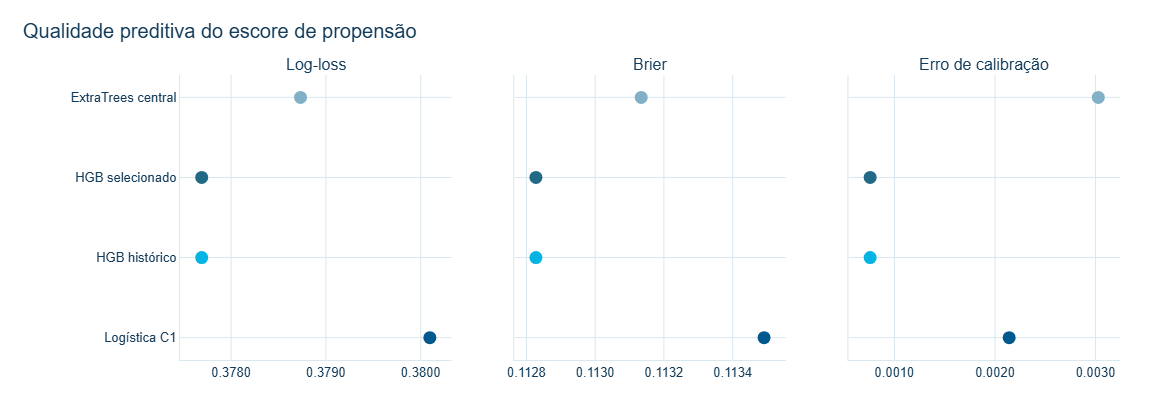

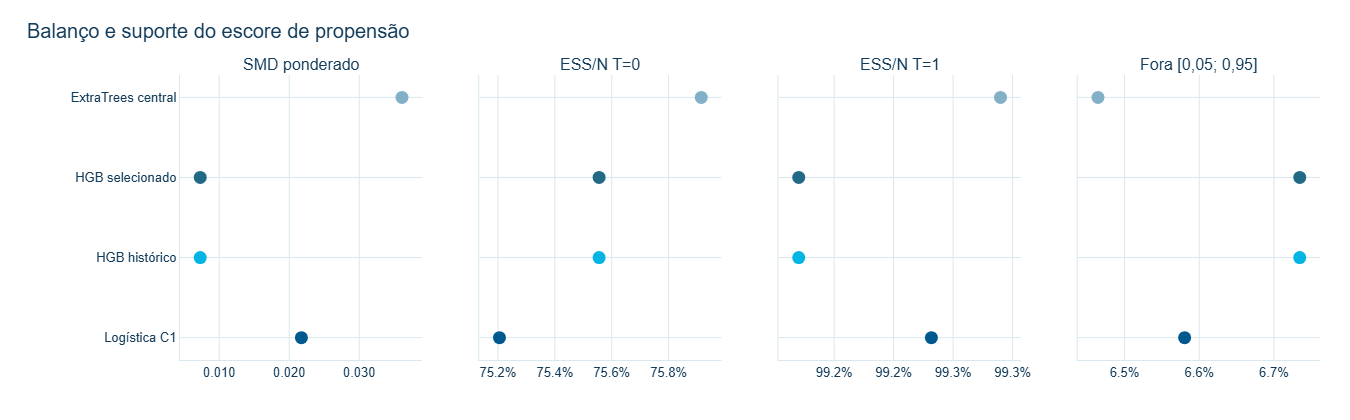

In [8]:
cores = {"logistica": "#00598E", "hgb_historico": "#04B4E3",
         "hgb": "#226986", "extra_trees": "#82B0C6"}
rotulo_modelo = {'logistica': 'Logística C1', 'hgb_historico': 'HGB histórico', 'hgb': 'HGB selecionado', 'extra_trees': 'ExtraTrees central'}
fig = make_subplots(rows=1, cols=3, shared_yaxes=True,
                    subplot_titles=["Log-loss", "Brier", "Erro de calibração"])
for coluna, metrica in enumerate(
    ("log_loss", "brier", "erro_calibracao_medio"), 1
):
    for _, linha in propensity_modelos.iterrows():
        fig.add_trace(go.Scatter(
            x=[linha[metrica]], y=[rotulo_modelo[linha.familia]], mode="markers",
            marker=dict(size=13, color=cores[linha.familia]),
            showlegend=False,
            hovertemplate=f"{linha.familia}<br>{metrica}: %{{x:.6f}}<extra></extra>",
        ), row=1, col=coluna)
    fig.update_xaxes(tickformat=".4f", row=1, col=coluna)
fig.update_layout(width=1150, height=420)
aplicar_tema_ipt(fig, "Qualidade preditiva do propensity")
fig.update_layout(margin=dict(l=180, r=30, t=75, b=60))
fig.show()
fig_guard = make_subplots(
    rows=1, cols=4, shared_yaxes=True,
    subplot_titles=["SMD ponderado", "ESS/N T=0", "ESS/N T=1", "Fora [0,05; 0,95]"],
)
for coluna, metrica in enumerate(
    ("max_abs_smd_ponderado", "ess_t0_sobre_n", "ess_t1_sobre_n",
     "fora_005_095_fracao"), 1
):
    for _, linha in propensity_modelos.iterrows():
        fig_guard.add_trace(go.Scatter(
            x=[linha[metrica]], y=[rotulo_modelo[linha.familia]], mode="markers",
            marker=dict(size=13, color=cores[linha.familia]),
            showlegend=False,
            hovertemplate=f"{linha.familia}<br>{metrica}: %{{x:.4f}}<extra></extra>",
        ), row=1, col=coluna)
    fig_guard.update_xaxes(tickformat=".3f" if coluna == 1 else ".1%", row=1, col=coluna)
fig_guard.update_layout(width=1350, height=420)
aplicar_tema_ipt(fig_guard, "Balanço e suporte do propensity")
fig_guard.update_layout(margin=dict(l=180, r=30, t=75, b=60))
fig_guard.show()

## 11. Propensity — decisão

Recomendação de sensibilidade exige ganho além de 1 EP, consistência em três folds e guardrails. O baseline não é substituído.

In [9]:
p0 = propensity_modelos.loc[propensity_modelos.familia.eq("logistica")].iloc[0]
avaliacao_propensity = []
for _, r in propensity_modelos.loc[~propensity_modelos.familia.eq("logistica")].iterrows():
    folds_alt = pd.read_csv(pasta_saida / f"propensity_{r.familia}_folds.csv")
    perdas_base = [f["externo_log_loss"] for f in r08b["folds"]]
    melhora_folds = [b - a for b, a in zip(perdas_base, folds_alt.log_loss)]
    guardrails = (r.max_abs_smd_ponderado <= .10 and r.ess_t0_sobre_n >= .20
                  and r.ess_t1_sobre_n >= .20 and r.fora_005_095_fracao <= .10
                  and r.ess_t0_sobre_n >= p0.ess_t0_sobre_n - .02
                  and r.ess_t1_sobre_n >= p0.ess_t1_sobre_n - .02
                  and r.fora_005_095_fracao <= p0.fora_005_095_fracao + .01
                  and r.max_abs_smd_ponderado <= p0.max_abs_smd_ponderado + .01)
    material = r.log_loss < p0.log_loss - r.log_loss_se_folds
    avaliacao_propensity.append({"familia": r.familia, "ganho_absoluto_log_loss": p0.log_loss-r.log_loss,
                                 "ganho_relativo": (p0.log_loss-r.log_loss)/p0.log_loss,
                                 "folds_melhorados": sum(v > 0 for v in melhora_folds),
                                 "guardrails": bool(guardrails), "alem_um_ep": bool(material),
                                 "recomendar": bool(guardrails and material and all(v > 0 for v in melhora_folds))})
avaliacao_propensity = pd.DataFrame(avaliacao_propensity)
display(avaliacao_propensity)
decisao_propensity = ("PROPENSITY_SENSIBILIDADE_ML_RECOMENDADA"
                      if len(avaliacao_propensity) and avaliacao_propensity.recomendar.any()
                      else "PROPENSITY_BASELINE_MANTIDO")
print(decisao_propensity)

,familia,ganho_absoluto_log_loss,ganho_relativo,folds_melhorados,guardrails,alem_um_ep,recomendar
0,hgb_historico,0.002407,0.006332,3,True,True,True
1,hgb,0.002407,0.006332,3,True,True,True
2,extra_trees,0.001364,0.003589,3,False,True,False


PROPENSITY_SENSIBILIDADE_ML_RECOMENDADA


## 12. Outcome model T=0

Seleção e OOF somente em observações com T=0. Prevalência e média predita são reportadas para avaliar calibração.

In [10]:
resumos_t0 = []
for familia in familias:
    if piloto[(piloto.alvo == "outcome_t0") & (piloto.familia == familia)].iloc[0].status != "VIAVEL":
        print("OUTCOME T=0", familia, "excluído por falha técnica")
        continue
    if familia == "hgb":
        resultado = executar_bloco("outcome_t0", familia, historico=True)
        resumos_t0.append(salvar_bloco("outcome_t0", familia, resultado, "hgb_historico"))
        del resultado
        gc.collect()
        if len(plano['outcome_t0']['hgb']) == 1:
            continue
    resultado = executar_bloco("outcome_t0", familia)
    resumos_t0.append(salvar_bloco("outcome_t0", familia, resultado))
    del resultado
    gc.collect()
outcome_t0 = pd.DataFrame(resumos_t0)
salvar_csv(outcome_t0, "outcome_t0_modelos_2024.csv")
display(outcome_t0[["familia", "log_loss", "brier", "auc", "erro_calibracao_medio",
                    "media_predita", "prevalencia"]])

,familia,log_loss,brier,auc,erro_calibracao_medio,media_predita,prevalencia
0,logistica,0.301650,0.082269,0.584855,0.001812,0.091229,0.09123
1,hgb_historico,0.301125,0.082183,0.590476,0.001430,0.091248,0.09123
2,hgb,0.301125,0.082183,0.590476,0.001430,0.091248,0.09123
3,extra_trees,0.301690,0.082282,0.584911,0.001816,0.091212,0.09123


## 13. Outcome model T=1

O mesmo protocolo é repetido independentemente em T=1.

In [11]:
resumos_t1 = []
for familia in familias:
    if piloto[(piloto.alvo == "outcome_t1") & (piloto.familia == familia)].iloc[0].status != "VIAVEL":
        print("OUTCOME T=1", familia, "excluído por falha técnica")
        continue
    if familia == "hgb":
        resultado = executar_bloco("outcome_t1", familia, historico=True)
        resumos_t1.append(salvar_bloco("outcome_t1", familia, resultado, "hgb_historico"))
        del resultado
        gc.collect()
        if len(plano['outcome_t1']['hgb']) == 1:
            continue
    resultado = executar_bloco("outcome_t1", familia)
    resumos_t1.append(salvar_bloco("outcome_t1", familia, resultado))
    del resultado
    gc.collect()
outcome_t1 = pd.DataFrame(resumos_t1)
salvar_csv(outcome_t1, "outcome_t1_modelos_2024.csv")
display(outcome_t1[["familia", "log_loss", "brier", "auc", "erro_calibracao_medio",
                    "media_predita", "prevalencia"]])

,familia,log_loss,brier,auc,erro_calibracao_medio,media_predita,prevalencia
0,logistica,0.269067,0.070736,0.571736,0.000833,0.076992,0.076992
1,hgb_historico,0.268412,0.070634,0.580612,0.000675,0.076998,0.076992
2,hgb,0.268412,0.070634,0.580612,0.000675,0.076998,0.076992
3,extra_trees,0.268874,0.070704,0.574635,0.000695,0.076996,0.076992


## 14. Comparação macro dos outcomes

Média simples de T=0 e T=1: cada braço tem peso igual na escolha, apesar da diferença de N.

,familia,log_loss,brier,auc,erro_calibracao_medio,erro_calibracao_maximo,prevalencia,media_predita,log_loss_se_folds
0,logistica,0.285359,0.076503,0.578295,0.001322,0.002404,0.084111,0.084111,0.000091
1,hgb,0.284769,0.076408,0.585544,0.001052,0.002045,0.084111,0.084123,0.000101
2,extra_trees,0.285282,0.076493,0.579773,0.001255,0.002434,0.084111,0.084104,0.000047
3,hgb_historico,0.284769,0.076408,0.585544,0.001052,0.002045,0.084111,0.084123,0.000101


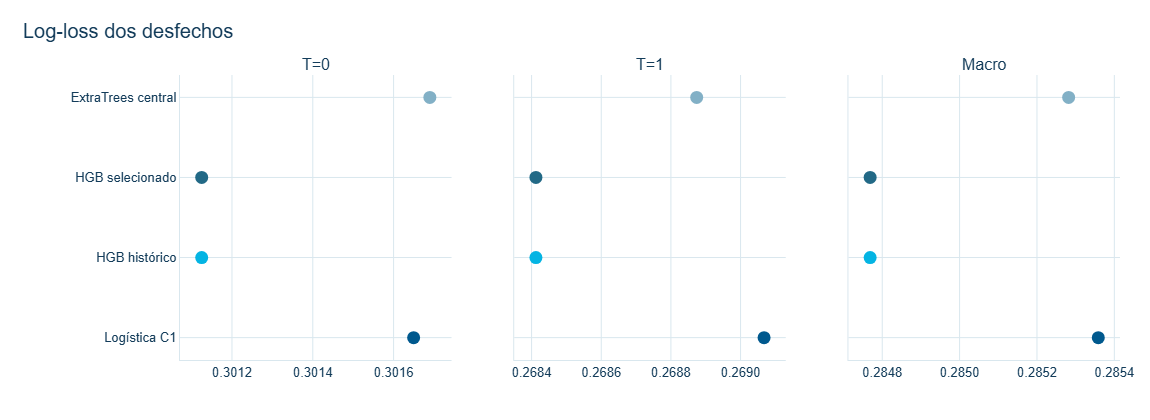

In [12]:
macro_linhas = []
for familia in (*familias, "hgb_historico"):
    a = outcome_t0[outcome_t0.familia.eq(familia)]
    b = outcome_t1[outcome_t1.familia.eq(familia)]
    if len(a) and len(b):
        macro_linhas.append({
            "familia": familia,
            **media_macro(a.iloc[0].to_dict(), b.iloc[0].to_dict()),
            "log_loss_se_folds": float(np.mean([
                a.iloc[0].log_loss_se_folds, b.iloc[0].log_loss_se_folds,
            ])),
        })
outcome_macro = pd.DataFrame(macro_linhas)
salvar_csv(outcome_macro, "outcome_macro_2024.csv")
display(outcome_macro)
fig_out = make_subplots(rows=1, cols=3, shared_yaxes=True,
                        subplot_titles=["T=0", "T=1", "Macro"])
for coluna, tabela in enumerate((outcome_t0, outcome_t1, outcome_macro), 1):
    for _, linha in tabela.iterrows():
        fig_out.add_trace(go.Scatter(
            x=[linha.log_loss], y=[rotulo_modelo[linha.familia]], mode="markers",
            marker=dict(size=13, color=cores[linha.familia]),
            showlegend=False,
            hovertemplate=f"{linha.familia}<br>Log-loss: %{{x:.6f}}<extra></extra>",
        ), row=1, col=coluna)
    fig_out.update_xaxes(tickformat=".4f", row=1, col=coluna)
fig_out.update_layout(width=1150, height=420)
aplicar_tema_ipt(fig_out, "Log-loss dos outcomes")
fig_out.update_layout(margin=dict(l=180, r=30, t=75, b=60))
fig_out.show()

## 15. Custo computacional

Fases executadas em sequência. O custo real inclui apenas fits novos nesta sessão; o baseline 08B certificado foi reutilizado.

,alvo,familia,fits_previstos,fits_certificados,segundos_certificados,baseline_08b_reutilizado
0,propensity,logistica,3,0,0.000000,True
1,propensity,hgb_historico,3,3,74.233701,False
2,propensity,hgb,75,75,1307.754843,False
3,propensity,extra_trees,3,3,2137.796528,False
4,outcome_t0,logistica,3,3,8.153627,False
5,outcome_t0,hgb_historico,3,3,7.390673,False
6,outcome_t0,hgb,75,75,138.516456,False
7,outcome_t0,extra_trees,3,3,112.494066,False
8,outcome_t1,logistica,3,3,46.229687,False
9,outcome_t1,hgb_historico,3,3,58.974921,False


,custo
fits_benchmark_certificados,249.000000
fits_piloto,12.000000
fits_grade_interrompida,1.000000
fits_totais_novos,262.000000
segundos_benchmark_certificados,6655.764839
segundos_piloto,55.740593
segundos_grade_interrompida,386.997308
baseline_08b_fits_reutilizados,48.000000
segundos_totais_fits,7098.502740


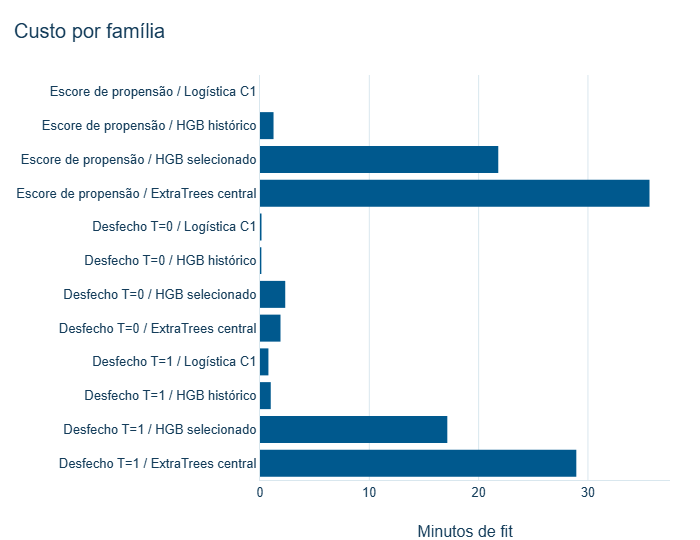

In [13]:
modelos_executados = pd.concat(
    [propensity_modelos, outcome_t0, outcome_t1], ignore_index=True
)
def custo_certificado(alvo, familia):
    fam_modelo = "hgb" if familia == "hgb_historico" else familia
    if alvo == "propensity" and familia == "logistica":
        return 0, 0.0
    pasta = (pasta_cache / "historico" if familia == "hgb_historico" else
             pasta_cache / "central" if familia == "extra_trees" else pasta_cache)
    registros = [
        json.loads(arq.read_text(encoding="utf-8"))
        for arq in pasta.glob(f"{alvo}_{fam_modelo}_*.json")
    ]
    registros = [r for r in registros if r.get("status") == "CONCLUIDO"
                 and "segundos" in r]
    return len(registros), float(sum(r["segundos"] for r in registros))
runtime_linhas = []
for _, linha in modelos_executados.iterrows():
    fits, segundos = custo_certificado(linha.alvo, linha.familia)
    esperado = (0 if linha.alvo == "propensity" and linha.familia == "logistica"
                else linha.fits_previstos)
    assert fits == esperado
    runtime_linhas.append({
        "alvo": linha.alvo, "familia": linha.familia,
        "fits_previstos": linha.fits_previstos,
        "fits_certificados": fits, "segundos_certificados": segundos,
        "baseline_08b_reutilizado": bool(
            linha.alvo == "propensity" and linha.familia == "logistica"
        ),
    })
runtime = pd.DataFrame(runtime_linhas)
salvar_csv(runtime, "benchmark_runtime.csv")
interrompidos = [
    json.loads(arq.read_text(encoding="utf-8"))
    for arq in pasta_cache.glob("propensity_extra_trees_*inner*.json")
]
custo_acumulado = {
    "fits_benchmark_certificados": int(runtime.fits_certificados.sum()),
    "fits_piloto": len(piloto),
    "fits_grade_interrompida": len(interrompidos),
    "fits_totais_novos": int(runtime.fits_certificados.sum()) + len(piloto)
                        + len(interrompidos),
    "segundos_benchmark_certificados": float(runtime.segundos_certificados.sum()),
    "segundos_piloto": float(piloto.segundos.sum()),
    "segundos_grade_interrompida": float(sum(r["segundos"] for r in interrompidos)),
    "baseline_08b_fits_reutilizados": 48,
}
custo_acumulado["segundos_totais_fits"] = (
    custo_acumulado["segundos_benchmark_certificados"]
    + custo_acumulado["segundos_piloto"]
    + custo_acumulado["segundos_grade_interrompida"]
)
salvar_json_novo_ou_validar(custo_acumulado, "benchmark_custo_acumulado.json")
display(runtime, pd.Series(custo_acumulado, name="custo").to_frame())
fig_runtime = go.Figure(go.Bar(
    y=runtime.alvo.map({"propensity": "Propensity", "outcome_t0": "Outcome T=0", "outcome_t1": "Outcome T=1"}) + " / " + runtime.familia.map(rotulo_modelo),
    x=runtime.segundos_certificados / 60,
    orientation="h", marker_color="#00598E",
    hovertemplate="%{y}: %{x:.1f} min<extra></extra>",
))
fig_runtime.update_layout(height=540, xaxis_title="Minutos de fit", yaxis_title="")
aplicar_tema_ipt(fig_runtime, "Custo por família")
fig_runtime.update_layout(margin=dict(l=260, r=30, t=75, b=60))
fig_runtime.update_yaxes(autorange="reversed")
fig_runtime.show()

## 16. Modelos descartados por inviabilidade

RandomForest não entra automaticamente no nested. Falhas técnicas do piloto e configurações não executadas por projeção acima do orçamento são registradas explicitamente.

In [14]:
exclusoes = piloto.loc[piloto.status.ne("VIAVEL"), ["alvo", "familia", "status", "erro"]].copy()
rf = piloto.loc[piloto.familia.eq("random_forest"), ["alvo", "familia", "status"]].copy()
rf["motivo"] = "viabilidade medida; nested não pré-autorizado pela projeção de custo/RAM"
display(exclusoes, rf)

,alvo,familia,status,erro


,alvo,familia,status,motivo
3,propensity,random_forest,VIAVEL,viabilidade medida; nested não pré-autorizado ...
7,outcome_t0,random_forest,VIAVEL,viabilidade medida; nested não pré-autorizado ...
11,outcome_t1,random_forest,VIAVEL,viabilidade medida; nested não pré-autorizado ...


## 17. Especificações candidatas para o notebook 09

A decisão abaixo só usa métricas preditivas externas, calibração e custo. C1 e C2 históricos continuam disponíveis sem alteração.

In [15]:
historicos = outcome_macro[outcome_macro.familia.isin(['logistica', 'hgb_historico'])]
o0 = historicos.loc[historicos.log_loss.idxmin()]
alternativas = outcome_macro.loc[~outcome_macro.familia.isin(['logistica', 'hgb_historico'])]
avaliacao_outcome = []
for _, r in alternativas.iterrows():
    ganho = o0.log_loss - r.log_loss
    melhora_t0 = (outcome_t0[outcome_t0.familia.eq(o0.familia)].iloc[0].log_loss
                  > outcome_t0[outcome_t0.familia.eq(r.familia)].iloc[0].log_loss)
    melhora_t1 = (outcome_t1[outcome_t1.familia.eq(o0.familia)].iloc[0].log_loss
                  > outcome_t1[outcome_t1.familia.eq(r.familia)].iloc[0].log_loss)
    avaliacao_outcome.append({"familia": r.familia, "ganho_absoluto": ganho,
                              "ganho_relativo": ganho / o0.log_loss,
                              "alem_um_ep": bool(ganho > r.log_loss_se_folds),
                              "ambos_bracos": bool(melhora_t0 and melhora_t1),
                              "calibracao_aceitavel": bool(r.erro_calibracao_medio
                                                           <= o0.erro_calibracao_medio + .01)})
avaliacao_outcome = pd.DataFrame(avaliacao_outcome)
display(avaliacao_outcome)
recomendar_outcome = len(avaliacao_outcome) and bool(
    (avaliacao_outcome.alem_um_ep & avaliacao_outcome.ambos_bracos &
     avaliacao_outcome.calibracao_aceitavel).any())
decisao_outcome = "OUTCOME_ML_OTIMIZADO_RECOMENDADO" if recomendar_outcome else "OUTCOMES_HISTORICOS_MANTIDOS"
print(decisao_outcome)

,familia,ganho_absoluto,ganho_relativo,alem_um_ep,ambos_bracos,calibracao_aceitavel
0,hgb,0.000000,0.000000,False,False,True
1,extra_trees,-0.000513,-0.001802,False,False,True


OUTCOMES_HISTORICOS_MANTIDOS


## 18. Limitações e decisão final

Três folds fornecem EP impreciso. Ganho preditivo não garante redução de viés causal. O benchmark permanece parcial: a grade completa de ExtraTrees foi interrompida pela regra de orçamento pré-especificada, após projeção de 12,61 horas. A revisão humana aceitou essa pendência para fechar 08B/08C; isso não reclassifica o benchmark como completo. A identidade dos modelos históricos e o Parquet de 2024 são preservados. Nenhum efeito causal foi estimado nesta frente.

In [16]:
completo = all(len(plano[a][f]) == len(grades[f])
               for a in n_alvo for f in familias)
veredito_benchmark = ("BENCHMARK_NUISANCE_2024_CONCLUIDO" if completo
                      else "BENCHMARK_NUISANCE_2024_PARCIAL")
baseline_final = hashlib.sha256(parquet.read_bytes()).hexdigest()
assert baseline_final == parquet_sha
recomendadas = avaliacao_propensity.loc[avaliacao_propensity.recomendar, "familia"].tolist()
sensibilidade = ("hgb_historico" if "hgb_historico" in recomendadas else
                 recomendadas[0] if recomendadas else None)
assert not completo and horas_revisadas > 6
assert all(len(plano[a]['extra_trees']) == 1 for a in n_alvo)
assert decisao_propensity == 'PROPENSITY_SENSIBILIDADE_ML_RECOMENDADA'
assert decisao_outcome == 'OUTCOMES_HISTORICOS_MANTIDOS'
decisoes = {
    "benchmark": veredito_benchmark,
    "propensity": decisao_propensity,
    "sensibilidade_propensity": sensibilidade,
    "outcome": decisao_outcome,
    "baseline": "BASELINE_2024_PRESERVADO",
    "pendencia_extratrees": "ACEITA_POR_ORCAMENTO",
    "revisao_humana": "APROVADA",
    "fechamento": "PRONTO_PARA_FECHAR_08B_08C",
    "custo": custo_acumulado,
    "horas_projetadas_grade_completa_inicial": horas_full,
    "horas_revisadas_grade_completa": horas_revisadas,
    "parquet_sha256": parquet_sha,
    "plano": plano_serial,
    "restricoes": {
        "efeito_causal_calculado": False,
        "notebook_09_criado": False,
        "baseline_historico_sobrescrito": False,
    },
}
destino_decisao = pasta_saida / "decisao_modelos_nuisance.json"
if destino_decisao.exists():
    anterior = json.loads(destino_decisao.read_text(encoding="utf-8"))
    for chave in ("benchmark", "propensity", "outcome", "baseline",
                  "parquet_sha256", "plano", "restricoes"):
        assert anterior[chave] == decisoes[chave], f"Decis?o pr?via divergente: {chave}"
destino_decisao.write_text(
    json.dumps(decisoes, ensure_ascii=False, indent=2) + chr(10),
    encoding="utf-8",
)
display(pd.Series(decisoes, name="decis?o").to_frame())

,decis?o
benchmark,BENCHMARK_NUISANCE_2024_PARCIAL
propensity,PROPENSITY_SENSIBILIDADE_ML_RECOMENDADA
sensibilidade_propensity,hgb_historico
outcome,OUTCOMES_HISTORICOS_MANTIDOS
baseline,BASELINE_2024_PRESERVADO
pendencia_extratrees,ACEITA_POR_ORCAMENTO
revisao_humana,APROVADA
fechamento,PRONTO_PARA_FECHAR_08B_08C
custo,"{'fits_benchmark_certificados': 249, 'fits_pil..."
horas_projetadas_grade_completa_inicial,4.673944
